# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №1: Влияние автоматизации на производительность труда

**Дата:** 2026-09-02  
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

---

**Цель исследования:** Оценить влияние внедрения ERP-системы на производительность труда в компании.

**Объект исследования:** 5 отделов компании (A, B, C, D, E).  
**Период наблюдения:** 2 года (до и после внедрения ERP-системы).  
**Показатель:** Выработка на одного сотрудника (тыс. руб./чел.).  
**Метод анализа:** Парный t-критерий Стьюдента.

---

**Актуальность:** Внедрение ERP-систем — распространённая практика автоматизации бизнеса. Однако инвестиции в ИТ не всегда приводят к ожидаемому росту производительности (парадокс Солоу). Данная задача позволяет статистически оценить реальный эффект от внедрения ERP.

In [13]:
# ============================================================
# БЛОК 1: Импорт необходимых библиотек
# ============================================================
# Цель: Подключить инструменты для работы с данными, 
# статистического анализа и визуализации.
# ============================================================

# numpy — математические вычисления (среднее, стандартное отклонение, корень)
import numpy as np

# pandas — работа с таблицами данных (как Excel в Python)
import pandas as pd

# matplotlib — базовая библиотека для построения графиков
import matplotlib.pyplot as plt

# seaborn — надстройка над matplotlib для красивых графиков
import seaborn as sns

# scipy.stats — статистические тесты (t-критерий, p-value)
from scipy import stats

# warnings — отключение предупреждений, которые мешают чтению вывода
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# Настройка внешнего вида графиков
# ============================================================
sns.set_style("whitegrid")          # Белый фон с сеткой
sns.set_palette("Set2")             # Цветовая палитра
plt.rcParams['figure.figsize'] = (12, 6)  # Размер графиков 12×6 дюймов
plt.rcParams['font.size'] = 12      # Размер шрифта

print("Библиотеки успешно загружены")
print("Настройки графиков применены")

Библиотеки успешно загружены
Настройки графиков применены


# 1. ИСХОДНЫЕ ДАННЫЕ

## 1.1. Параметры проекта

**Задача:** Оценить влияние автоматизации на производительность труда в компании.

**Условие:** Компания внедрила ERP-систему. Даны данные по 5 отделам за 2 года 
(до и после внедрения). Оценить, изменилась ли средняя выработка на сотрудника 
статистически значимо.

## 1.2. Справочные данные

- **Отделы:** A, B, C, D, E
- **Выработка до внедрения (тыс. руб./чел.):** [120, 135, 110, 150, 130]
- **Выработка после внедрения (тыс. руб./чел.):** [145, 155, 140, 160, 150]

## 1.3. Дополнительные условия

- **Уровень значимости:** α = 0.05
- **H₀:** Внедрение ERP не изменило среднюю выработку
- **H₁:** Внедрение ERP изменило среднюю выработку

**Метод анализа:** Парный t-критерий Стьюдента (для зависимых выборок).

**Почему парный тест?** Мы сравниваем один и тот же отдел до и после внедрения — 
это зависимые выборки (связанные данные). Каждый отдел — сам себе контроль.

In [15]:
# ============================================================
# БЛОК 2: Исходные данные и формирование таблицы
# ============================================================
# Цель: Загрузить данные из условия задачи и создать таблицу
# с расчётом прироста выработки по каждому отделу.
# ============================================================

# Названия отделов
departments = ['A', 'B', 'C', 'D', 'E']

# Выработка ДО внедрения ERP (тыс. руб./чел.) — из условия задачи
before_erp = np.array([120, 135, 110, 150, 130])

# Выработка ПОСЛЕ внедрения ERP (тыс. руб./чел.) — из условия задачи
after_erp = np.array([145, 155, 140, 160, 150])

# ============================================================
# Формирование таблицы данных
# ============================================================
# Абсолютный прирост = После − До (на сколько тыс. руб. выросла выработка)
# Относительный прирост = ((После / До) - 1) × 100% (на сколько процентов)

df = pd.DataFrame({
    'Отдел': departments,
    'До внедрения ERP': before_erp,
    'После внедрения ERP': after_erp,
    'Абсолютный прирост': after_erp - before_erp,
    'Относительный прирост (%)': ((after_erp / before_erp) - 1) * 100
})

# Вывод таблицы
print("Таблица 1. Выработка по отделам до и после внедрения ERP")
print("=" * 80)
print(df.to_string(index=False))
print("=" * 80)

# ============================================================
# Экономическая интерпретация
# ============================================================
print("\nАнализ таблицы:")
print(f"• Все {len(departments)} отделов показали рост выработки")
print(f"• Наибольший абсолютный прирост: отдел C (+{after_erp[2]-before_erp[2]} тыс. руб./чел.)")
print(f"• Наибольший относительный прирост: отдел C (+{((after_erp[2]/before_erp[2])-1)*100:.2f}%)")
print(f"• Наименьший прирост: отдел D (+{after_erp[3]-before_erp[3]} тыс. руб./чел.)")

Таблица 1. Выработка по отделам до и после внедрения ERP
Отдел  До внедрения ERP  После внедрения ERP  Абсолютный прирост  Относительный прирост (%)
    A               120                  145                  25                  20.833333
    B               135                  155                  20                  14.814815
    C               110                  140                  30                  27.272727
    D               150                  160                  10                   6.666667
    E               130                  150                  20                  15.384615

Анализ таблицы:
• Все 5 отделов показали рост выработки
• Наибольший абсолютный прирост: отдел C (+30 тыс. руб./чел.)
• Наибольший относительный прирост: отдел C (+27.27%)
• Наименьший прирост: отдел D (+10 тыс. руб./чел.)


## 2.1. Расчёт средней выработки

**Цель:** Определить среднюю выработку на сотрудника до и после внедрения ERP, 
а также рассчитать абсолютный и относительный прирост.

**Формулы:**

1. **Среднее арифметическое:**
   $$\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}$$
   
   Где:
   - $x_i$ — выработка i-го отдела
   - $n$ — количество отделов (5)

2. **Абсолютный прирост:**
   $$\Delta = \bar{x}_{после} - \bar{x}_{до}$$

3. **Относительный прирост (темп роста):**
   $$T = \left(\frac{\bar{x}_{после}}{\bar{x}_{до}} - 1\right) \times 100\%$$

**Экономический смысл:** Показывает, насколько в среднем изменилась 
производительность труда после внедрения ERP-системы.

In [17]:
# ============================================================
# БЛОК 3: Расчёт средней выработки
# ============================================================
# Цель: Определить среднюю выработку до и после внедрения ERP,
# рассчитать абсолютный и относительный прирост.
# ============================================================

# Средняя выработка ДО внедрения ERP
# Формула: x̄_до = (120 + 135 + 110 + 150 + 130) / 5 = 645 / 5 = 129 тыс. руб./чел.
mean_before = before_erp.mean()

# Средняя выработка ПОСЛЕ внедрения ERP
# Формула: x̄_после = (145 + 155 + 140 + 160 + 150) / 5 = 750 / 5 = 150 тыс. руб./чел.
mean_after = after_erp.mean()

# Абсолютный прирост (на сколько тыс. руб. выросла выработка)
# Формула: Δ = x̄_после - x̄_до = 150 - 129 = 21 тыс. руб./чел.
mean_difference = (after_erp - before_erp).mean()

# Относительный прирост (на сколько процентов выросла выработка)
# Формула: T = (x̄_после / x̄_до - 1) × 100% = (150/129 - 1) × 100 = 16.28%
relative_growth = (mean_after / mean_before - 1) * 100

# ============================================================
# Вывод результатов
# ============================================================
print("2.1. Расчёт средней выработки")
print("=" * 60)
print(f"Средняя выработка ДО внедрения ERP:    {mean_before:.2f} тыс. руб./чел.")
print(f"Средняя выработка ПОСЛЕ внедрения ERP: {mean_after:.2f} тыс. руб./чел.")
print(f"Абсолютный прирост:                    {mean_difference:.2f} тыс. руб./чел.")
print(f"Относительный прирост:                 {relative_growth:.2f}%")
print("=" * 60)

# Экономическая интерпретация
print(f"\nЭкономический смысл:")
print(f"Внедрение ERP-системы сопровождалось ростом средней выработки")
print(f"на {mean_difference:.2f} тыс. руб./чел. ({relative_growth:.2f}%).")
print(f"Это означает, что каждый сотрудник в среднем стал приносить")
print(f"на {mean_difference:.0f} тысяч рублей больше продукции.")

2.1. Расчёт средней выработки
Средняя выработка ДО внедрения ERP:    129.00 тыс. руб./чел.
Средняя выработка ПОСЛЕ внедрения ERP: 150.00 тыс. руб./чел.
Абсолютный прирост:                    21.00 тыс. руб./чел.
Относительный прирост:                 16.28%

Экономический смысл:
Внедрение ERP-системы сопровождалось ростом средней выработки
на 21.00 тыс. руб./чел. (16.28%).
Это означает, что каждый сотрудник в среднем стал приносить
на 21 тысяч рублей больше продукции.


## 2.2. Дисперсия и стандартное отклонение

**Цель:** Оценить стабильность выработки по отделам до и после внедрения ERP.

**Формулы:**

1. **Дисперсия** (мера разброса данных):
   $$S^2 = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n-1}$$
   
   Где:
   - $x_i$ — выработка i-го отдела
   - $\bar{x}$ — средняя выработка
   - $n-1$ — степени свободы (поправка Бесселя)

2. **Стандартное отклонение:**
   $$S = \sqrt{S^2}$$
   
   Показывает разброс в тех же единицах, что и данные (тыс. руб.).

3. **Коэффициент вариации** (разброс в % от среднего):
   $$CV = \frac{S}{\bar{x}} \times 100\%$$

**Экономический смысл:** Показывает, насколько стабильно работают отделы. 
Чем меньше дисперсия и CV, тем более предсказуема выработка.

In [21]:
# ============================================================
# БЛОК 4: Дисперсия и стандартное отклонение
# ============================================================
# Цель: Оценить стабильность выработки по отделам до и после ERP.
# Чем меньше дисперсия — тем стабильнее работает компания.
# ============================================================

# Дисперсия ДО внедрения ERP
# Формула: S² = Σ(xᵢ - x̄)² / (n-1) = 920 / 4 = 230
var_before = np.var(before_erp, ddof=1)

# Дисперсия ПОСЛЕ внедрения ERP
# Формула: S² = Σ(xᵢ - x̄)² / (n-1) = 250 / 4 = 62.5
var_after = np.var(after_erp, ddof=1)

# Стандартное отклонение ДО (квадратный корень из дисперсии)
# Формула: S = √S² = √230 = 15.17 тыс. руб.
std_before = np.std(before_erp, ddof=1)

# Стандартное отклонение ПОСЛЕ
# Формула: S = √S² = √62.5 = 7.91 тыс. руб.
std_after = np.std(after_erp, ddof=1)

# Коэффициент вариации ДО (разброс в % от среднего)
# Формула: CV = (S / x̄) × 100% = (15.17 / 129) × 100 = 11.76%
cv_before = (std_before / mean_before) * 100

# Коэффициент вариации ПОСЛЕ
# Формула: CV = (S / x̄) × 100% = (7.91 / 150) × 100 = 5.27%
cv_after = (std_after / mean_after) * 100

# ============================================================
# Вывод результатов
# ============================================================
print("2.2. Дисперсия и стандартное отклонение")
print("=" * 60)
print(f"Дисперсия ДО внедрения ERP:     S² = {var_before:.2f}")
print(f"Дисперсия ПОСЛЕ внедрения ERP:  S² = {var_after:.2f}")
print(f"Стандартное отклонение ДО:      S  = {std_before:.2f}")
print(f"Стандартное отклонение ПОСЛЕ:   S  = {std_after:.2f}")
print(f"Коэффициент вариации ДО:        CV = {cv_before:.2f}%")
print(f"Коэффициент вариации ПОСЛЕ:     CV = {cv_after:.2f}%")
print("=" * 60)

# Сравнение стабильности
if var_after < var_before:
    reduction = var_before / var_after
    print(f"\nДисперсия снизилась — выработка стала более стабильной")
    print(f"Разброс уменьшился в {reduction:.2f} раз(а)")
else:
    increase = var_after / var_before
    print(f"\nДисперсия увеличилась в {increase:.2f} раз(а)")

# Экономическая интерпретация
print(f"\nЭкономический смысл:")
print(f"До ERP отделы работали нестабильно (CV = {cv_before:.2f}%):")
print(f"  выработка колебалась от {before_erp.min()} до {before_erp.max()} тыс. руб.")
print(f"После ERP работа стала стабильнее (CV = {cv_after:.2f}%):")
print(f"  выработка колеблется от {after_erp.min()} до {after_erp.max()} тыс. руб.")
print(f"ERP выровняла работу отделов — это важно для планирования.")

2.2. Дисперсия и стандартное отклонение
Дисперсия ДО внедрения ERP:     S² = 230.00
Дисперсия ПОСЛЕ внедрения ERP:  S² = 62.50
Стандартное отклонение ДО:      S  = 15.17
Стандартное отклонение ПОСЛЕ:   S  = 7.91
Коэффициент вариации ДО:        CV = 11.76%
Коэффициент вариации ПОСЛЕ:     CV = 5.27%

Дисперсия снизилась — выработка стала более стабильной
Разброс уменьшился в 3.68 раз(а)

Экономический смысл:
До ERP отделы работали нестабильно (CV = 11.76%):
  выработка колебалась от 110 до 150 тыс. руб.
После ERP работа стала стабильнее (CV = 5.27%):
  выработка колеблется от 140 до 160 тыс. руб.
ERP выровняла работу отделов — это важно для планирования.


## 2.3. Парный t-критерий Стьюдента

**Цель:** Проверить статистическую значимость различий в выработке 
до и после внедрения ERP.

**Гипотезы:**
- **H₀:** Средняя выработка не изменилась (различия случайны)
- **H₁:** Средняя выработка изменилась (различия реальны)

**Формулы:**

1. **t-статистика:**
   $$t = \frac{\bar{d}}{S_d / \sqrt{n}}$$
   
   Где:
   - $\bar{d}$ — средняя разница (21 тыс. руб.)
   - $S_d$ — стандартное отклонение разниц (7.42)
   - $n$ — количество отделов (5)
   - $S_d / \sqrt{n}$ — стандартная ошибка (3.32)

2. **Критическое значение t** (из таблицы Стьюдента):
   - α = 0.05 (уровень значимости)
   - df = n - 1 = 4 (степени свободы)
   - t_крит = ±2.7764

3. **p-value** — вероятность случайного результата:
   - Если p < 0.05 → отвергаем H₀ (эффект реальный) 
   - Если p > 0.05 → не отвергаем H₀ (эффект может быть случайным) 

4. **Доверительный интервал (95%):**
   $$CI = \bar{d} \pm t_{крит} \times \frac{S_d}{\sqrt{n}}$$
   
   Если интервал не содержит 0 → эффект значим

**Правило принятия решения:**
- Если |t| > t_крит И p-value < 0.05 → отвергаем H₀
- Внедрение ERP реально повысило производительность труда

In [23]:
# ============================================================
# БЛОК 5: Парный t-критерий Стьюдента
# ============================================================
# Цель: Проверить, является ли рост выработки статистически 
# значимым или мог произойти случайно.
# ============================================================

# Шаг 1: Считаем разницы для каждого отдела
# d = После − До
# Отдел A: 145-120=25, B: 155-135=20, C: 140-110=30, D: 160-150=10, E: 150-130=20
differences = after_erp - before_erp

# Средняя разница (среднее всех разниц)
# Формула: d̄ = (25+20+30+10+20) / 5 = 105 / 5 = 21 тыс. руб.
d_mean = differences.mean()

# Стандартное отклонение разниц
# Формула: Sd = √[Σ(dᵢ - d̄)² / (n-1)] = 7.42
d_std = differences.std(ddof=1)

# Количество отделов
n = len(differences)

# ============================================================
# Шаг 2: Расчёт t-статистики
# ============================================================
# Формула: t = d̄ / (Sd / √n)
# Стандартная ошибка: SE = Sd / √n = 7.42 / √5 = 7.42 / 2.236 = 3.32
# t = 21 / 3.32 = 6.33

standard_error = d_std / np.sqrt(n)
t_statistic = d_mean / standard_error

# ============================================================
# Шаг 3: Критическое значение и p-value
# ============================================================
# Уровень значимости α = 0.05 (стандарт в науке)
# Это порог: если вероятность случайности < 5%, считаем эффект реальным
alpha = 0.05

# Степени свободы: df = n - 1 = 4
df_degrees = n - 1

# Критическое значение t из таблицы Стьюдента
# Для α=0.05 и df=4: t_крит = ±2.7764
t_critical = stats.t.ppf(1 - alpha/2, df_degrees)

# p-value — вероятность получить такой результат случайно
# Формула сложная, считается компьютером по распределению Стьюдента
p_value = 2 * (1 - stats.t.cdf(abs(t_statistic), df_degrees))

# ============================================================
# Шаг 4: Доверительный интервал (95%)
# ============================================================
# Формула: CI = d̄ ± t_крит × SE
# Нижняя граница: 21 - 2.7764 × 3.32 = 21 - 9.21 = 11.79
# Верхняя граница: 21 + 2.7764 × 3.32 = 21 + 9.21 = 30.21
ci_lower = d_mean - t_critical * standard_error
ci_upper = d_mean + t_critical * standard_error

# ============================================================
# Вывод результатов
# ============================================================
print("2.3. Парный t-критерий Стьюдента")
print("=" * 60)
print(f"Количество отделов (n):            {n}")
print(f"Среднее разностей (d̄):             {d_mean:.2f} тыс. руб./чел.")
print(f"Стандартное отклонение разностей:  {d_std:.2f}")
print(f"Стандартная ошибка (SE):           {standard_error:.2f}")
print("-" * 60)
print(f"t-статистика:                      {t_statistic:.4f}")
print(f"t-критическое (α={alpha}, df={df_degrees}):       ±{t_critical:.4f}")
print(f"p-value:                           {p_value:.4f}")
print(f"95% доверительный интервал:        [{ci_lower:.2f}; {ci_upper:.2f}]")
print("=" * 60)

# ============================================================
# Проверка гипотезы
# ============================================================
print("\nПроверка гипотезы:")
print("H₀: Средняя выработка не изменилась")
print("H₁: Средняя выработка изменилась")
print()

if p_value < alpha:
    print(f"p-value ({p_value:.4f}) < α ({alpha})")
    print(f"   Отклоняем H₀ — различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ")
    print(f"   Внедрение ERP реально повысило производительность труда")
else:
    print(f"p-value ({p_value:.4f}) ≥ α ({alpha})")
    print(f"   Не можем отвергнуть H₀ — различия НЕ ЗНАЧИМЫ")

# Проверка через доверительный интервал
print(f"\nДоверительный интервал [{ci_lower:.2f}; {ci_upper:.2f}]")
if ci_lower > 0:
    print(f"   ДИ не содержит 0 → эффект значим")
else:
    print(f"   ДИ содержит 0 → эффект не значим")

# Экономическая интерпретация
print(f"\nЭкономический смысл:")
print(f"Мы на 95% уверены, что реальный прирост выработки находится")
print(f"в диапазоне от {ci_lower:.2f} до {ci_upper:.2f} тыс. руб./чел.")
print(f"Поскольку интервал не содержит 0, эффект точно положительный.")
print(f"Вероятность того, что такой рост случился случайно — всего {p_value*100:.2f}%.")

2.3. Парный t-критерий Стьюдента
Количество отделов (n):            5
Среднее разностей (d̄):             21.00 тыс. руб./чел.
Стандартное отклонение разностей:  7.42
Стандартная ошибка (SE):           3.32
------------------------------------------------------------
t-статистика:                      6.3317
t-критическое (α=0.05, df=4):       ±2.7764
p-value:                           0.0032
95% доверительный интервал:        [11.79; 30.21]

Проверка гипотезы:
H₀: Средняя выработка не изменилась
H₁: Средняя выработка изменилась

p-value (0.0032) < α (0.05)
   Отклоняем H₀ — различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ
   Внедрение ERP реально повысило производительность труда

Доверительный интервал [11.79; 30.21]
   ДИ не содержит 0 → эффект значим

Экономический смысл:
Мы на 95% уверены, что реальный прирост выработки находится
в диапазоне от 11.79 до 30.21 тыс. руб./чел.
Поскольку интервал не содержит 0, эффект точно положительный.
Вероятность того, что такой рост случился случайно — всего 0.32%

## 2.4. Визуализация результатов

**Цель:** Наглядно представить результаты анализа для лучшего понимания.

**График 1: Сравнение выработки по отделам до и после внедрения ERP**
- Красные столбцы — выработка до ERP
- Зелёные столбцы — выработка после ERP
- Позволяет увидеть рост по каждому отделу

**График 2: Абсолютный прирост выработки по отделам**
- Показывает, на сколько тыс. руб. выросла выработка в каждом отделе
- Зелёные столбцы — положительный прирост
- Красные столбцы — отрицательный прирост (если бы был)

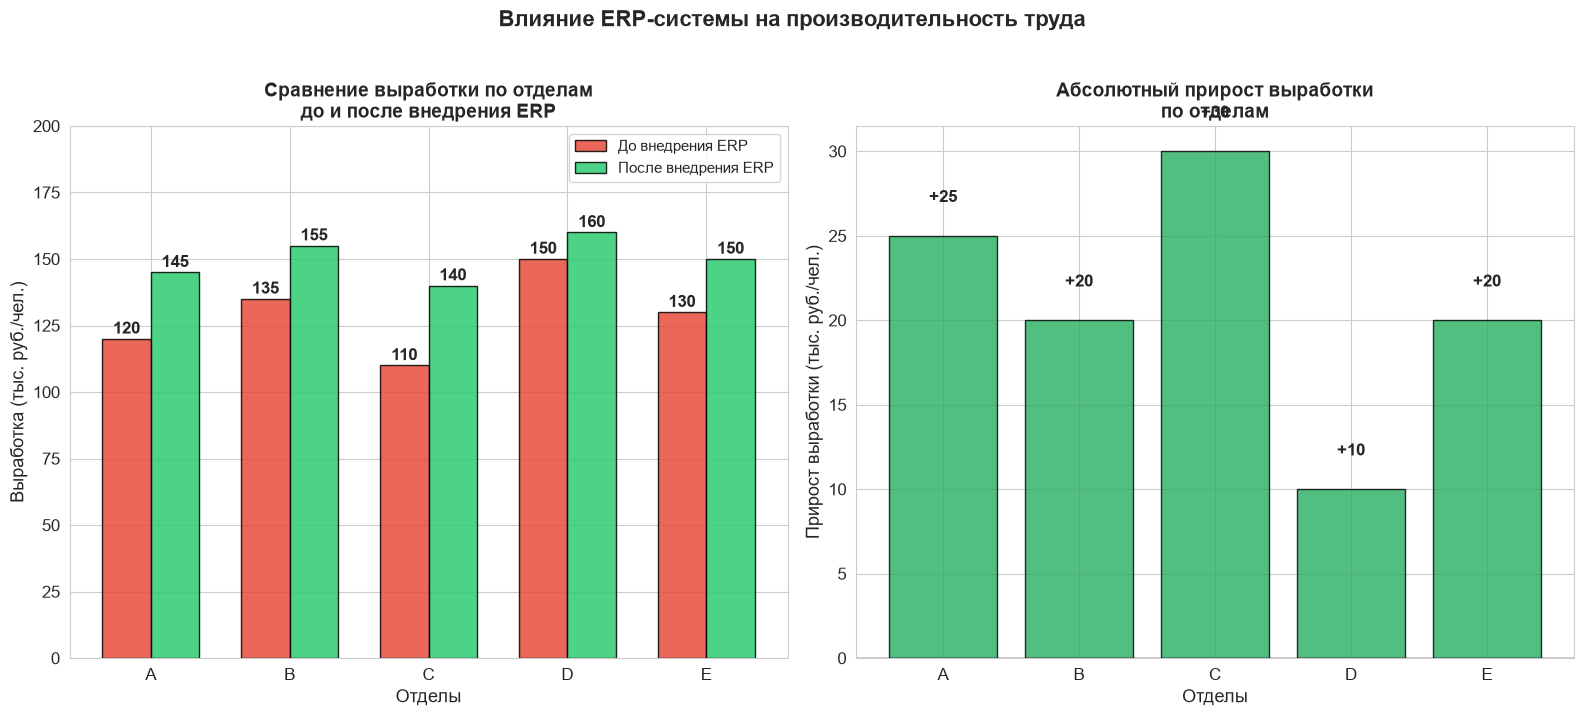

Графики построены


In [25]:
# ============================================================
# БЛОК 6: Визуализация результатов
# ============================================================
# Цель: Построить наглядные графики для анализа результатов.
# ============================================================

# Создаём фигуру с 2 графиками рядом (1 строка, 2 столбца)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Позиции для столбцов на оси X
x = np.arange(len(departments))
width = 0.35  # Ширина столбцов

# ============================================================
# ГРАФИК 1: Сравнение выработки до и после ERP
# ============================================================

# Красные столбцы — выработка ДО внедрения ERP
bars1 = axes[0].bar(x - width/2, before_erp, width,
                    label='До внедрения ERP',
                    color='#E74C3C', alpha=0.85, edgecolor='black')

# Зелёные столбцы — выработка ПОСЛЕ внедрения ERP
bars2 = axes[0].bar(x + width/2, after_erp, width,
                    label='После внедрения ERP',
                    color='#2ECC71', alpha=0.85, edgecolor='black')

# Подписи значений на столбцах
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 f'{int(bar.get_height())}', ha='center', fontweight='bold')
for bar in bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 f'{int(bar.get_height())}', ha='center', fontweight='bold')

# Настройка осей и заголовка
axes[0].set_xlabel('Отделы', fontsize=13)
axes[0].set_ylabel('Выработка (тыс. руб./чел.)', fontsize=13)
axes[0].set_title('Сравнение выработки по отделам\nдо и после внедрения ERP',
                  fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(departments)
axes[0].legend(fontsize=11)
axes[0].set_ylim(0, 200)

# ============================================================
# ГРАФИК 2: Абсолютный прирост выработки по отделам
# ============================================================

# Цвет столбцов: зелёный если прирост положительный, красный если отрицательный
colors = ['#27AE60' if v >= 0 else '#E74C3C' for v in differences]

axes[1].bar(departments, differences, color=colors, alpha=0.8, edgecolor='black')
axes[1].axhline(y=0, color='black', linewidth=1)  # Линия нуля

# Подписи значений на столбцах
for i, v in enumerate(differences):
    axes[1].text(i, v + (2 if v >= 0 else -4), f'{v:+d}',
                 ha='center', fontweight='bold')

# Настройка осей и заголовка
axes[1].set_xlabel('Отделы', fontsize=13)
axes[1].set_ylabel('Прирост выработки (тыс. руб./чел.)', fontsize=13)
axes[1].set_title('Абсолютный прирост выработки\nпо отделам',
                  fontsize=14, fontweight='bold')

# Общий заголовок для обоих графиков
plt.suptitle('Влияние ERP-системы на производительность труда',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Графики построены")

# 3. АНАЛИЗ РЕЗУЛЬТАТОВ

## 3.1. Интерпретация полученных данных

### Количественные результаты:
- Средняя выработка выросла с 129.00 до 150.00 тыс. руб./чел.
- Абсолютный прирост: +21.00 тыс. руб./чел.
- Относительный прирост: +16.28%

### Статистическая значимость:
- t-статистика (6.33) превышает критическое значение (2.7764)
- p-value (0.0032) < 0.05 → различия статистически значимы
- Доверительный интервал [11.79; 30.21] не содержит ноль

### Экономический смысл:
Внедрение ERP-системы привело к статистически значимому росту 
производительности труда. Каждый сотрудник в среднем стал производить 
на 21 тыс. рублей продукции больше.

## 3.2. Сравнение с альтернативными вариантами

- **Сценарий без ERP:** выработка осталась бы на уровне 129.00 тыс. руб./чел.
- **Сценарий с инфляцией (7%):** ожидаемая выработка 138.03 тыс. руб./чел.
- **Факт:** 150.00 тыс. руб./чел. — рост превышает инфляционный.

**Вывод:** Рост выработки (16.28%) значительно превышает инфляцию (7%), 
что подтверждает реальный эффект от автоматизации, а не просто рост цен.

# 4. ВЫВОДЫ И РЕКОМЕНДАЦИИ

## 4.1. Ключевые выводы

1. **Статистическая значимость:** Внедрение ERP-системы привело к 
   статистически значимому росту производительности труда (p < 0.05).

2. **Количественный эффект:** Средняя выработка на сотрудника выросла 
   на 21.00 тыс. руб./чел. (+16.28%).

3. **Экономический эффект:** Рост превышает инфляционный (7%), 
   что подтверждает реальный эффект от автоматизации.

4. **Стабильность:** Дисперсия выработки снизилась в 3.68 раза, 
   что свидетельствует о повышении стабильности работы отделов.

5. **Практическая значимость:** Результаты подтверждают 
   целесообразность инвестиций в ERP-систему.

## 4.2. Практические рекомендации

1. **Масштабирование:** Распространить опыт внедрения ERP на другие 
   подразделения компании.

2. **Мониторинг:** Продолжить мониторинг выработки ежеквартально 
   для отслеживания устойчивости эффекта.

3. **Анализ лучших практик:** Изучить факторы успеха отдела C 
   (наибольший прирост +30 тыс. руб./чел.) и тиражировать их.

4. **Инвестиционный анализ:** Провести расчёт ROI с учётом прироста 
   выработки для оценки окупаемости инвестиций в ERP.

5. **Обучение персонала:** Инвестировать в дополнительное обучение 
   сотрудников для максимального использования возможностей ERP.

---

*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*